In [1]:
import numpy as np
from matplotlib import pyplot as plt
import copy

In [2]:
def Gaussian_overlap(vec1, vec2):
    N = len(vec1) // 2
    
    U1 = vec1[: N, N :]
    V1 = vec1[N :, N :]
    W1 = np.zeros((2 * N, 2 * N), dtype = "complex128")
    W1[:N, :N] = U1
    W1[N:, :N] = V1
    W1[:N, N:] = np.conj(V1)
    W1[N:, N:] = np.conj(U1)

    U2 = vec2[: N, N :]
    V2 = vec2[N :, N :]
    W2 = np.zeros((2 * N, 2 * N), dtype = "complex128")
    W2[:N, :N] = U2
    W2[N:, :N] = V2
    W2[:N, N:] = np.conj(V2)
    W2[N:, N:] = np.conj(U2)
    
    W = np.conj(W1).T @ W2
    
    U = W[:N, :N]
    ov = np.linalg.det(U)
    
    eig_U, vec_U = np.linalg.eig(U)
    
    BP = 0.5 * np.sum(np.imag(np.log(eig_U)))
    
    return ((BP / np.pi) % 1) * np.pi, ov

In [3]:
def Ham_tbc(Lx, Ly, mu, t, Delta, theta_x, theta_y):
    Ht = np.zeros((Lx * Ly, Lx * Ly), dtype = "complex128")
    for i in range(Lx):
        for j in range(Ly):
            ind0 = i + j * Lx
            indx = (i + 1) % Lx + j * Lx
            
            if i != Lx - 1:
                Ht[ind0, indx] = - 1
                Ht[indx, ind0] = - 1
            else:
                Ht[ind0, indx] = - np.exp(1j * theta_x)
                Ht[indx, ind0] = - np.exp(- 1j * theta_x)
        
    for i in range(Lx):
        for j in range(Ly):
            ind0 = i + j * Lx
            indy = i + ((j + 1) % Ly) * Lx
        
            if j != Ly - 1:
                Ht[ind0, indy] = - 1
                Ht[indy, ind0] = - 1
            else:
                Ht[ind0, indy] = - np.exp(1j * theta_y)
                Ht[indy, ind0] = - np.exp(- 1j * theta_y)
            
    Hd = np.zeros((Lx * Ly, Lx * Ly), dtype = "complex128")
    for i in range(Lx):
        for j in range(Ly):
            ind0 = i + j * Lx
            indx = (i + 1) % Lx + j * Lx
        
            if i != Lx - 1:
                Hd[ind0, indx] = - 1j
                Hd[indx, ind0] = 1j
            else:
                Hd[ind0, indx] = - 1j * np.exp(1j * theta_x)
                Hd[indx, ind0] = 1j *  np.exp(- 1j * theta_x)
        
    for i in range(Lx):
        for j in range(Ly):
            ind0 = i + j * Lx
            indy = i + ((j + 1) % Ly) * Lx

            if j != Ly - 1:
                Hd[ind0, indy] = - 1
                Hd[indy, ind0] = 1
            else:
                Hd[ind0, indy] = - np.exp(1j * theta_y)
                Hd[indy, ind0] = np.exp(- 1j * theta_y)

    Hd1 = np.zeros((Lx * Ly, Lx * Ly), dtype = "complex128")
    for i in range(Lx):
        for j in range(Ly):
            ind0 = i + j * Lx
            indx = (i + 1) % Lx + j * Lx
                
            if i != Lx - 1:
                Hd1[ind0, indx] = - 1j
                Hd1[indx, ind0] = 1j
            else:
                Hd1[ind0, indx] = - 1j * np.cos(theta_x)
                Hd1[indx, ind0] = 1j *  np.cos(theta_x)
                
    for i in range(Lx):
        for j in range(Ly):
            ind0 = i + j * Lx
            indy = i + ((j + 1) % Ly) * Lx
        
            if j != Ly - 1:
                Hd1[ind0, indy] = - 1
                Hd1[indy, ind0] = 1
            else:
                Hd1[ind0, indy] = - np.cos(theta_y)
                Hd1[indy, ind0] = np.cos(theta_y)
            
    Hm = np.eye(Lx * Ly, dtype = "complex128")
    
    HD = np.zeros((2 * Lx * Ly, 2 * Lx * Ly), dtype = "complex128")
    HD[: Lx * Ly, Lx * Ly: ] = - 0.5 * Hm
    HD[Lx * Ly :, : Lx * Ly] = 0.5 * Hm
    HD[: Lx * Ly, : Lx * Ly] = Hd1
    HD[Lx * Ly :, Lx * Ly :] = - Hd1
    

    Htemp = np.zeros((2 * Lx * Ly, 2 * Lx * Ly), dtype = "complex128")
    Htemp[:Lx * Ly, :Lx * Ly] = Ht - mu * Hm
    Htemp[Lx * Ly:, Lx * Ly:] = - Ht + mu * Hm
    Htemp[:Lx * Ly, Lx * Ly:] = t * Hd
    Htemp[Lx * Ly:, :Lx * Ly] = t * np.conj(Hd).T 
    
    H = np.zeros((4 * Lx * Ly, 4 * Lx * Ly), dtype = "complex128")
    
    H[: 2 * Lx * Ly, : 2 * Lx * Ly] = Htemp
    H[2 * Lx * Ly :, 2 * Lx * Ly :] = - np.conj(Htemp)
    
    H[: 2 * Lx * Ly, 2 * Lx * Ly :] = Delta * HD
    H[2 * Lx * Ly :, : 2 * Lx * Ly] = Delta * np.conj(HD).T
    
    return H

In [6]:
def Berry_phase(mu, Delta, Lx, Ly):

    theta_values1 = np.pi * np.linspace(0, 1, 100)
    theta_values2 = np.pi * np.linspace(1, 2, 100)

    t = 1

    overlap = []
    BP = 0
    BP_coll = []
    gap = []
    Energy = []

    H = Ham_tbc(Lx, Ly, mu, t, Delta, theta_x = 0, theta_y = 0)
    eigs, vec = np.linalg.eigh(H)
    Energy.append(eigs)

    vec0 = copy.deepcopy(vec)

    for theta in theta_values1[1:]:
    
        H = Ham_tbc(Lx, Ly, mu, t, Delta, theta_x = theta, theta_y = 0)
        eigs1, vec1 = np.linalg.eigh(H)
    
        Energy.append(eigs1)
    
        gap_temp = np.min(np.abs(eigs1))
        gap.append(gap_temp)
    
        BP_temp, ov = Gaussian_overlap(vec0, vec1)
        BP += BP_temp
        BP_coll.append(((BP / np.pi) % 1) * np.pi)
        overlap.append(ov)
    
        vec0 = copy.deepcopy(vec1)
    
    for theta in theta_values1[1:]:
    
        H = Ham_tbc(Lx, Ly, mu, t, Delta, theta_x = np.pi, theta_y = theta)
        eigs1, vec1 = np.linalg.eigh(H)
    
        Energy.append(eigs1)
    
        gap_temp = np.min(np.abs(eigs1))
        gap.append(gap_temp)
    
        BP_temp, ov = Gaussian_overlap(vec0, vec1)
        BP += BP_temp
        BP_coll.append(((BP / np.pi) % 1) * np.pi)
        overlap.append(ov)
    
        vec0 = copy.deepcopy(vec1)
    
    for theta in theta_values2:
    
        H = Ham_tbc(Lx, Ly, mu, t, Delta, theta_x = theta, theta_y = np.pi)
        eigs1, vec1 = np.linalg.eigh(H)
    
        Energy.append(eigs1)
    
        gap_temp = np.min(np.abs(eigs1))
        gap.append(gap_temp)
    
        BP_temp, ov = Gaussian_overlap(vec0, vec1)
        BP += BP_temp
        BP_coll.append(((BP / np.pi) % 1) * np.pi)
        overlap.append(ov)
    
        vec0 = copy.deepcopy(vec1)
    
    for theta in theta_values2:
    
        H = Ham_tbc(Lx, Ly, mu, t, Delta, theta_x = 2 * np.pi, theta_y = theta)
        eigs1, vec1 = np.linalg.eigh(H)
    
        Energy.append(eigs1)
    
        gap_temp = np.min(np.abs(eigs1))
        gap.append(gap_temp)
    
        BP_temp, ov = Gaussian_overlap(vec0, vec1)
        BP += BP_temp
        BP_coll.append(((BP / np.pi) % 1) * np.pi)
        overlap.append(ov)
    
        vec0 = copy.deepcopy(vec1)
    

    vec1 = copy.deepcopy(vec)
    
    BP_temp, ov = Gaussian_overlap(vec0, vec1)
    BP += BP_temp
    BP_coll.append(((BP / np.pi) % 1) * np.pi)
    overlap.append(ov)
    
    return ((BP / np.pi) % 1) * np.pi, Energy

In [7]:
Lx = 6
Ly = 6

mu = - 5
Delta = 0.25

BP, energy_mu_m5 = Berry_phase(mu, Delta, Lx, Ly)

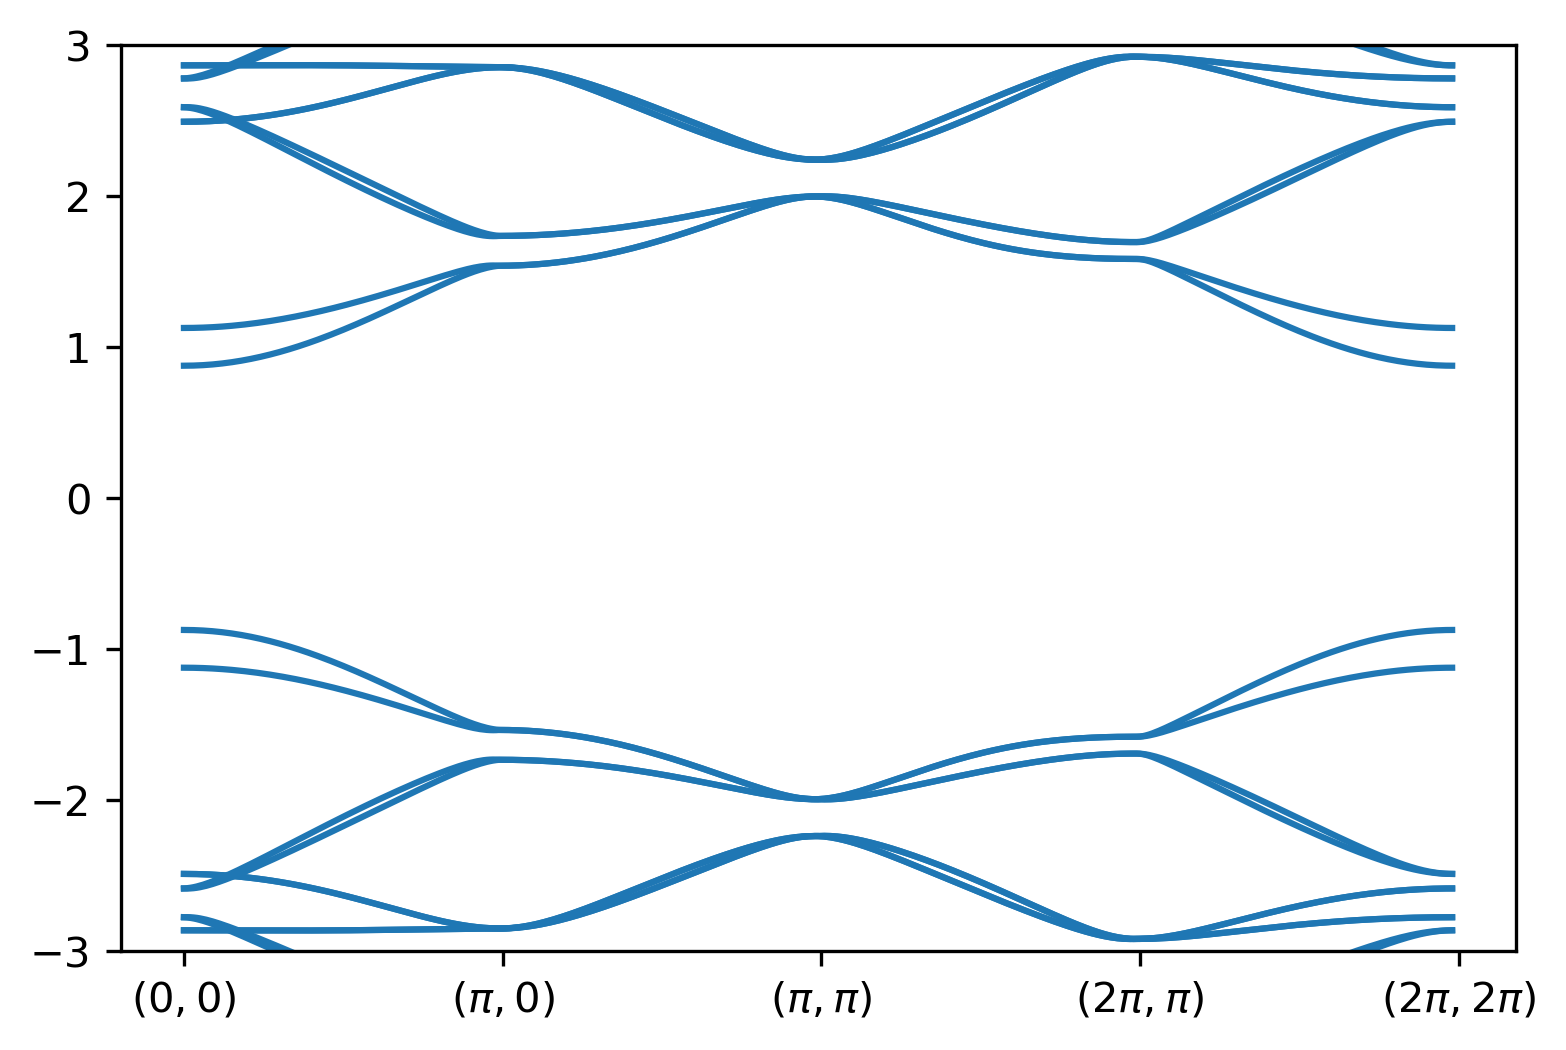

In [27]:
plt.figure(dpi = 300)
plt.plot(energy_mu_m5, color = "tab:blue")
plt.ylim(-3,3)
plt.xticks([0,100,200,300,400], labels = [r"$(0,0)$", r"$(\pi,0)$",r"$(\pi,\pi)$",r"$(2\pi,\pi)$", r"$(2\pi,2\pi)$"])
# plt.xticklabels([r"$(0,0)$", r"$(\pi,0)$",r"$(\pi,\pi)$",r"$(2\pi,\pi)$", r"$(2\pi,2\pi)$"])
plt.show()

In [10]:
Lx = 6
Ly = 6

mu = - 4
Delta = 0.25

BP, energy_mu_m4 = Berry_phase(mu, Delta, Lx, Ly)

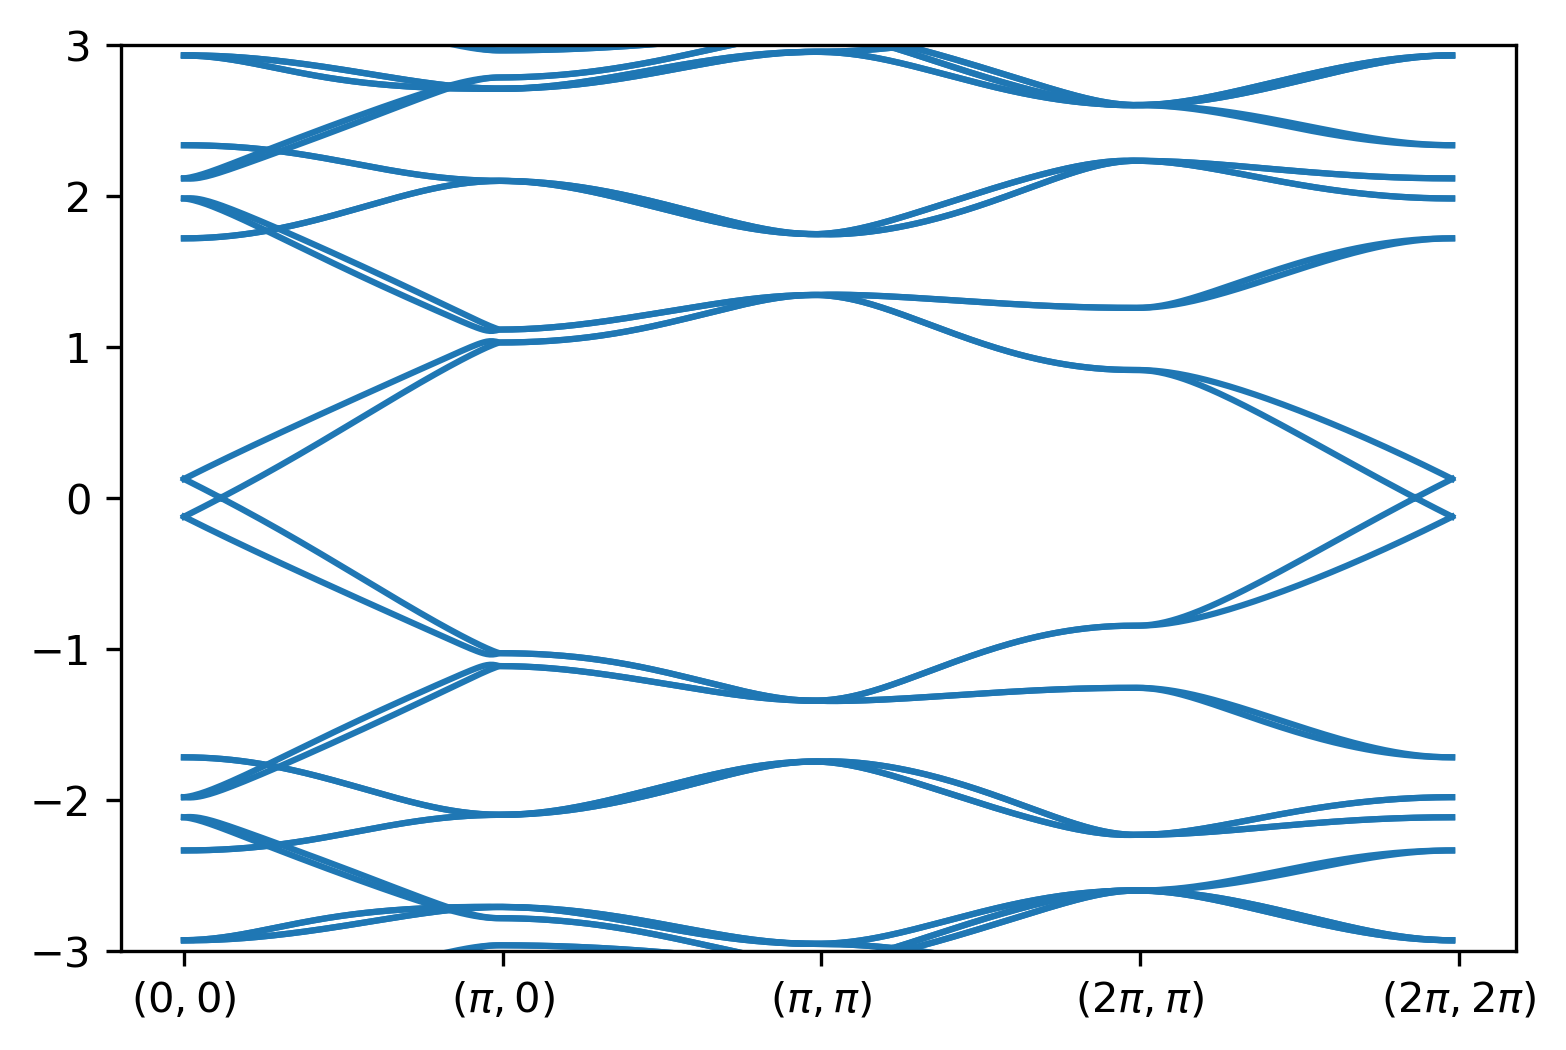

In [28]:
plt.figure(dpi = 300)
plt.plot(energy_mu_m4, color = "tab:blue")
plt.ylim(-3,3)
plt.xticks([0,100,200,300,400], labels = [r"$(0,0)$", r"$(\pi,0)$",r"$(\pi,\pi)$",r"$(2\pi,\pi)$", r"$(2\pi,2\pi)$"])
plt.show()

In [12]:
Lx = 6
Ly = 6

mu = - 2
Delta = 0.25

BP, energy_mu_m2 = Berry_phase(mu, Delta, Lx, Ly)

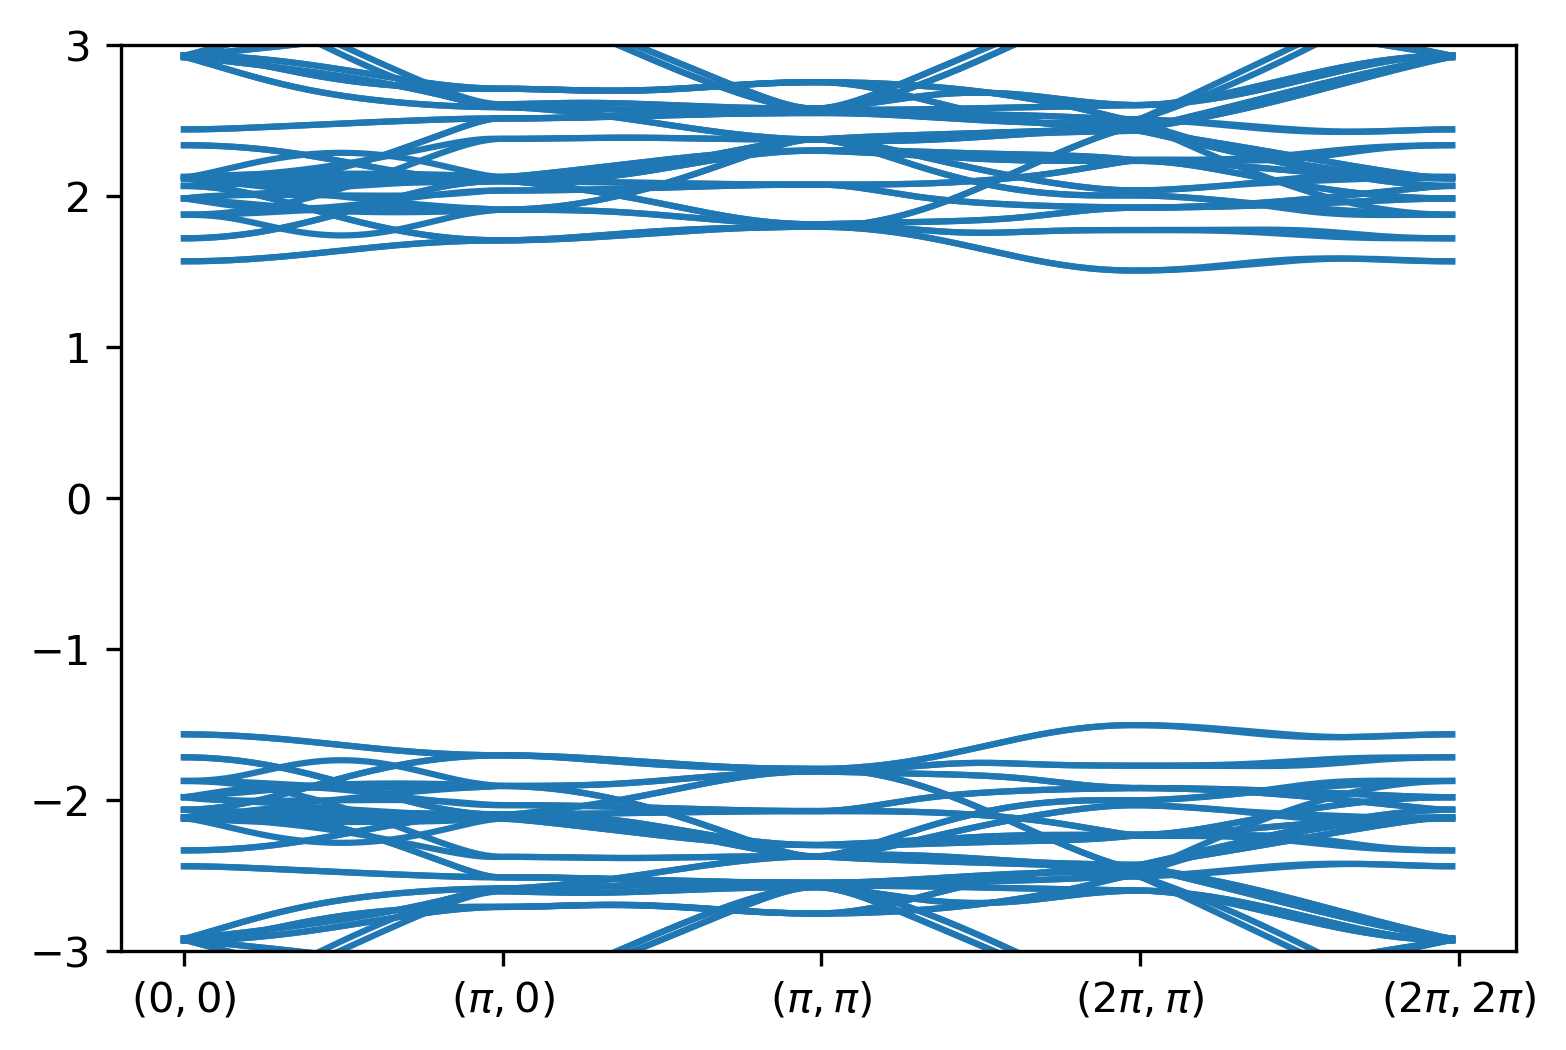

In [29]:
plt.figure(dpi = 300)
plt.plot(energy_mu_m2, color = "tab:blue")
plt.ylim(-3,3)
plt.xticks([0,100,200,300,400], labels = [r"$(0,0)$", r"$(\pi,0)$",r"$(\pi,\pi)$",r"$(2\pi,\pi)$", r"$(2\pi,2\pi)$"])
plt.show()